# Credit Risk Scorecard: Give Me Some Credit

**Goal.** Build a points-based credit scorecard that ranks borrowers by their chance of becoming seriously delinquent, using the standard industry approach: bin each variable, convert the bins to Weight of Evidence (WoE), fit a logistic regression and scale its output to points.

**Data.** [Give Me Some Credit](https://www.kaggle.com/c/GiveMeSomeCredit) (Kaggle): 150,000 borrowers and 10 predictors. The target `SeriousDlqin2yrs` is 1 if the borrower became 90 or more days past due within two years. 6.68% of borrowers did.

**Headline result (held-out test set, 45,000 borrowers).** AUC 0.858, Gini 0.716, KS 0.554. The default rate falls from 36% in the lowest-scoring 10% of borrowers to 0.5% in the highest-scoring 10%.

**Contents**
1. Profile the data
2. Clean the data
3. Train/test split
4. WoE and information value (IV) for every variable
5. Model and scorecard points
6. Evaluation on the test set
7. Limitations and next steps

## 0. Setup and data loading
Load the raw file into `df`. From here on `df` is never modified: every change happens on a copy (`df_clean`), so the profiling numbers can always be reproduced.

In [1]:
import pandas as pd 


In [2]:
data_path = "../data/cs-training.csv"

df = pd.read_csv(data_path)

# Structural dimensions
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")


Rows: 150000, Columns: 12


## 1. Profile the data
**Purpose:** find problems in the data before any modelling.

The file has 12 columns: the target, 10 predictors and a row-number column (`Unnamed: 0`), which is dropped during cleaning. Checks below: data types and non-null counts, the first rows, and missing values.

In [3]:
#data types, non null counts and memory footprint
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  

In [4]:
#first 5 items 
df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [5]:
#find nulls
df.isnull().sum()


Unnamed: 0                                  0
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

**Missing values.** Only two columns have gaps: `MonthlyIncome` (29,731 missing, 19.82%) and `NumberOfDependents` (3,924 missing, 2.62%).

### 1.1 Placeholder codes and other anomalies
The three past due columns count how many times a borrower was 30 to 59, 60 to 89 or 90+ days late. The next cell looks for impossible counts (the special codes 96, 98, 99 and 999), measures their default rate, and checks age, income, dependents and utilisation for anything odd.

In [6]:
past_due_columns = ['NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfTimes90DaysLate']
codes = [99,96,98,999]

result = []
for col in past_due_columns:
    for code in codes:
        rows_with_code = df[col] == code #returns rows with T or F where code matched
        n = rows_with_code.sum() #we sum all T as 1s
        result.append(
            {
                "column":col,
                "rows":n,
                "code":code,
                "default rows": df.loc[rows_with_code,"SeriousDlqin2yrs"].sum(),
                "default %": round(df.loc[rows_with_code,"SeriousDlqin2yrs"].mean() * 100,2)
            }

        )

placeholder_summary = pd.DataFrame([res for res in result if res["rows"] > 0])

placeholders = df[past_due_columns].isin([96,98,99,999]).any(axis=1)

check_anomalies = {
    "Age = 0" : len(df[df["age"] == 0]),
    "Age > 96" : len(df[df["age"] > 96]),
    "Missing monthly income %" : round(df["MonthlyIncome"].isnull().mean() * 100,2),
    "Missing dependents %" : round(df["NumberOfDependents"].isnull().mean() * 100,2),
    "Utilization of unsecured credit == 1" : len(df[df["RevolvingUtilizationOfUnsecuredLines"] == 1]),
    "Utilization of unsecured credit > 1" : len(df[df["RevolvingUtilizationOfUnsecuredLines"] > 1]),
    "Total placeholder rows" : int(placeholders.sum()),
    "Default rate with placeholders %" : round(df.loc[placeholders,"SeriousDlqin2yrs"].mean() * 100, 2),
    "Overall default rate %" : round((df["SeriousDlqin2yrs"] == 1).mean() * 100,2)
}

print(placeholder_summary,"\n")
print(pd.Series(check_anomalies))


                                 column  rows  code  default rows  default %
0  NumberOfTime30-59DaysPastDueNotWorse     5    96             4      80.00
1  NumberOfTime30-59DaysPastDueNotWorse   264    98           143      54.17
2  NumberOfTime60-89DaysPastDueNotWorse     5    96             4      80.00
3  NumberOfTime60-89DaysPastDueNotWorse   264    98           143      54.17
4               NumberOfTimes90DaysLate     5    96             4      80.00
5               NumberOfTimes90DaysLate   264    98           143      54.17 

Age = 0                                    1.00
Age > 96                                  45.00
Missing monthly income %                  19.82
Missing dependents %                       2.62
Utilization of unsecured credit == 1      17.00
Utilization of unsecured credit > 1     3321.00
Total placeholder rows                   269.00
Default rate with placeholders %          54.65
Overall default rate %                     6.68
dtype: float64


**Findings.**
- Codes 96 and 98 appear (5 and 264 rows), always for the same borrowers in all three past due columns: 269 borrowers in total. Codes 99 and 999 do not appear.
- Those 269 borrowers default at **54.65%**, against 6.68% overall, so they form a distinct and very risky group rather than random errors.
- Age 0 occurs once (invalid). 45 borrowers are older than 96.
- Utilisation is above 1 for 3,321 borrowers.

### 1.2 Debt ratio
`DebtRatio` is monthly debt payments divided by monthly income, so values above about 1 mean debts exceed income. The cell below looks at its distribution, the default rate by band, and whether it behaves differently when income is missing.

In [7]:
ratio = df["DebtRatio"]
target = df["SeriousDlqin2yrs"]

# 1. Shape of the data
print(ratio.describe(percentiles=[0.5, 0.9, 0.99, 0.999]))

# 2. Default rate by band
bands = pd.cut(ratio, [-0.001, 0.25, 0.5, 1, 2, 5, 100, 1000, float("inf")])
print(target.groupby(bands, observed=True).agg(["count", "mean"]))

# 3. Does it behave differently when income is missing?
missing = df["MonthlyIncome"].isnull()
print("income missing:\n", ratio[missing].describe(percentiles=[0.5, 0.9]))
print("income present:\n", ratio[~missing].describe(percentiles=[0.5, 0.9]))

count    150000.000000
mean        353.005076
std        2037.818523
min           0.000000
50%           0.366508
90%        1267.000000
99%        4979.040000
99.9%     10613.074000
max      329664.000000
Name: DebtRatio, dtype: float64
                 count      mean
DebtRatio                       
(-0.001, 0.25]   52361  0.059701
(0.25, 0.5]      41347  0.061165
(0.5, 1.0]       21155  0.098322
(1.0, 2.0]        4092  0.131720
(2.0, 5.0]        1399  0.078628
(5.0, 100.0]      5266  0.044056
(100.0, 1000.0]   7488  0.077591
(1000.0, inf]    16892  0.049076
income missing:
 count     29731.000000
mean       1673.396556
std        4248.372895
min           0.000000
50%        1159.000000
90%        3785.000000
max      329664.000000
Name: DebtRatio, dtype: float64
income present:
 count    120269.000000
mean         26.598777
std         424.446457
min           0.000000
50%           0.296023
90%           0.763149
max       61106.500000
Name: DebtRatio, dtype: float64


**Findings.**
- The median is 0.37, but the 90th percentile is 1,267 and the maximum is 329,664. These are not real ratios.
- Where income is present the ratio looks sensible (median 0.30, 90th percentile 0.76). Where income is missing the median is 1,159, which looks like a money amount rather than a ratio.
- 24,380 borrowers have a ratio above 100. 93% of them also have no income recorded. The remaining 1,687 default at 4.1%, below average, so they do not look like genuinely over-leveraged borrowers either.

### Step 1 summary: dataset problems and decisions
| Problem | Evidence | Decision |
|---|---|---|
| Placeholder codes 96 and 98 in the past due columns | 269 borrowers, 54.65% default, undocumented | Add one flag column, blank the fake counts, bin the blanks as their own "Missing" group |
| Age 0 | 1 row | Remove the row |
| Age above 96 | 45 rows, 6.7% default, plausible | Keep; the top age bin absorbs them |
| Missing monthly income | 19.82%; missing-income borrowers default at 5.61% against 6.95% | Keep the blanks as their own bin, because the missingness carries signal |
| Missing dependents | 2.62%, all also missing income; default 4.56% against 6.74% | Keep the blanks as their own bin |
| Utilisation above 1 | 3,321 rows, mostly genuine over-limit borrowers | Keep. 241 values above 10 default at about the average and look like errors, but are left unchanged for simplicity (this slightly dilutes the top risk bin) |
| Debt ratio above 100 | 24,380 rows, not plausible as a ratio | Blank, then bin as "Missing" |
| `Unnamed: 0` | CSV row number | Drop |

## 2. Clean the data
All cleaning happens on a copy, so the raw `df` stays untouched. The order matters: the placeholder flag is created **before** the fake counts are blanked, otherwise the flag would find nothing.

1. Remove the borrower with age 0.
2. Create `placeholder_flag` (1 if any past due column holds 96 or 98).
3. Blank the 96 and 98 values in the three past due columns.
4. Blank debt ratios above 100.
5. Drop the CSV row-number column.

In [8]:
import numpy as np

#drop age = 0
df_clean = df[df["age"] > 0].copy()

#create a new column placeholder flag 
df_clean["placeholder_flag"] = df_clean[past_due_columns].isin([96,98]).any(axis=1).astype(int)

#make placeholders blank in all three past due columns with np.nan
df_clean[past_due_columns] =  df_clean[past_due_columns].replace([96,98],np.nan)

#Setting debt ratio to np.nan where its above 100
df_clean.loc[df_clean["DebtRatio"] > 100,"DebtRatio"] = np.nan

#drop the csv row number column Unamed: 0
df_clean = df_clean.drop(columns="Unnamed: 0")


## 3. Train/test split
The data is split **before** any binning, so that bins, WoE values and model coefficients are learned from the training set only. The test set is used once, at the end, to measure performance on borrowers the model has never seen.

- `test_size=0.3`: 30% of borrowers go to the test set.
- `stratify=y`: keeps the default rate identical in both sets.
- `random_state=0`: fixes the shuffle so the split is reproducible.

In [9]:
from sklearn.model_selection import train_test_split

x = df_clean.drop(columns='SeriousDlqin2yrs')
y = df_clean["SeriousDlqin2yrs"]

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.3,random_state=0,stratify=y)

print(len(x_train), len(x_test))
print(round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2))

104999 45000
6.68 6.68


Result: 104,999 training and 45,000 test borrowers, with a 6.68% default rate in both.

## 4. Weight of evidence (WoE) and information value (IV)
Each variable is cut into groups (bins). For every bin we compare the share of all good borrowers in it with the share of all bad borrowers in it:

- **WoE = ln(share of good borrowers in the bin / share of bad borrowers in the bin).** Positive means safer than average, negative means riskier, near 0 means average.
- **IV = sum over bins of (good share - bad share) x WoE.** One number per variable that says how well it separates good from bad borrowers.

| IV | Predictive power |
|---|---|
| below 0.02 | useless |
| 0.02 to 0.1 | weak |
| 0.1 to 0.3 | medium |
| 0.3 to 0.5 | strong |
| above 0.5 | very strong (check for leakage) |

The function below builds the table (counts, default rate, shares, WoE, IV) for any binned variable. Missing values get their own "Missing" bin instead of being filled in.

In [10]:
def woe_iv_table(binned, y):
    t = y.groupby(binned, observed=True).agg(["sum", "count"])
    t.columns = ["bad", "total"]

    t["good"] = t["total"] - t["bad"]
    t["bad_rate"] = t["bad"] / t["total"]
    t["good%"] = t["good"] / t["good"].sum()
    t["bad%"] = t["bad"] / t["bad"].sum()
    t["WOE"] = np.log(t["good%"] / t["bad%"])
    t["IV"] = (t["good%"] - t["bad%"]) * t["WOE"]
    
    print(f"Total IV:", round(t["IV"].sum(), 4))
    return t



### 4.1 Age
Ten groups with roughly equal numbers of borrowers (`pd.qcut`).

In [11]:
age_table = woe_iv_table(pd.qcut(x_train["age"], q=10), y_train)
age_table

Total IV: 0.2528


,bad,total,good,bad_rate,good%,bad%,WOE,IV
age,,,,,,,,
"(20.999, 33.0]",1367,11916,10549,0.114720,0.107664,0.194785,-0.592883,0.051653
"(33.0, 39.0]",996,10533,9537,0.094560,0.097335,0.141921,-0.377108,0.016814
"(39.0, 44.0]",952,11112,10160,0.085673,0.103694,0.135651,-0.268647,0.008585
"(44.0, 48.0]",814,10351,9537,0.078640,0.097335,0.115987,-0.175321,0.003270
"(48.0, 52.0]",790,10367,9577,0.076203,0.097743,0.112568,-0.141209,0.002093
"(52.0, 56.0]",686,9960,9274,0.068876,0.094651,0.097749,-0.032203,0.000100
"(56.0, 60.0]",470,9386,8916,0.050075,0.090997,0.066971,0.306575,0.007366
"(60.0, 65.0]",454,11434,10980,0.039706,0.112063,0.064691,0.549438,0.026028
"(65.0, 72.0]",273,9942,9669,0.027459,0.098682,0.038900,0.930913,0.055652


**Age result.** IV 0.25 (medium). The default rate falls steadily from 11.5% in the youngest group to 2.2% in the oldest, and WoE rises from -0.59 to +1.18 with no reversals. Borrowers under about 56 are riskier than average, older borrowers are safer.

### 4.2 Utilisation (`RevolvingUtilizationOfUnsecuredLines`)
Balance as a share of the credit limit. Ten equal-sized groups, with the group edges kept (`retbins=True`) so they can be reused on the test set.

In [12]:
util_binned, util_edges = pd.qcut(
    x_train["RevolvingUtilizationOfUnsecuredLines"], q=10, retbins=True, duplicates="drop"
)
print(util_edges)

util_table = woe_iv_table(util_binned, y_train)
util_table

[0.00000000e+00 3.02166440e-03 1.94477708e-02 4.36367972e-02
 8.31644710e-02 1.54232702e-01 2.71555052e-01 4.43976592e-01
 6.98176611e-01 9.80204676e-01 5.07080000e+04]
Total IV: 1.1105


,bad,total,good,bad_rate,good%,bad%,WOE,IV
RevolvingUtilizationOfUnsecuredLines,,,,,,,,
"(-0.001, 0.00302]",251,10500,10249,0.023905,0.104602,0.035765,1.073187,0.073875
"(0.00302, 0.0194]",135,10500,10365,0.012857,0.105786,0.019236,1.704620,0.147534
"(0.0194, 0.0436]",165,10500,10335,0.015714,0.105480,0.023511,1.501051,0.123039
"(0.0436, 0.0832]",187,10500,10313,0.017810,0.105255,0.026646,1.373757,0.107990
"(0.0832, 0.154]",258,10500,10242,0.024571,0.104530,0.036763,1.044997,0.070817
"(0.154, 0.272]",373,10499,10126,0.035527,0.103347,0.053149,0.664988,0.033381
"(0.272, 0.444]",561,10500,9939,0.053429,0.101438,0.079937,0.238205,0.005122
"(0.444, 0.698]",934,10500,9566,0.088952,0.097631,0.133086,-0.309801,0.010984
"(0.698, 0.98]",1711,10500,8789,0.162952,0.089701,0.243802,-0.999872,0.154081


**Utilisation result.** IV 1.11, the strongest variable. The default rate rises from 1.3% to 23.3% across the bins. The top bin (above 0.98) carries over a third of the IV. One quirk: the very lowest bin (almost no usage) defaults slightly more (2.4%) than the next one (1.3%), possibly inactive or thin-file accounts.

### 4.3 Past due counts (30 to 59, 60 to 89, 90+ days late)
These are small counts that are mostly 0, so equal-sized groups would not work. The groups are chosen by hand: 0, 1, 2 and 3 or more, plus a "Missing" group for the blanked placeholder codes.

In [13]:
bins = [-1, 0, 1, 2, np.inf]
labels = ["0", "1", "2", "3+"]

past_due_tables = {}

for col in past_due_columns:
    binned = pd.cut(x_train[col], bins=bins, labels=labels)
    binned = binned.cat.add_categories("Missing").fillna("Missing")

    print("\n====", col, "====")
    past_due_tables[col] = woe_iv_table(binned, y_train)
    print(past_due_tables[col])


==== NumberOfTime30-59DaysPastDueNotWorse ====
Total IV: 0.7584
                                       bad  total   good  bad_rate     good%  \
NumberOfTime30-59DaysPastDueNotWorse                                           
0                                     3532  88307  84775  0.039997  0.865219   
1                                     1708  11178   9470  0.152800  0.096651   
2                                      828   3186   2358  0.259887  0.024066   
3+                                     847   2146   1299  0.394688  0.013258   
Missing                                103    182     79  0.565934  0.000806   

                                          bad%       WOE        IV  
NumberOfTime30-59DaysPastDueNotWorse                                
0                                     0.503277  0.541841  0.196115  
1                                     0.243374 -0.923489  0.135497  
2                                     0.117982 -1.589739  0.149303  
3+                           

**Past due results.** All three are very strong (IV 0.76, 0.59 and 0.87 for 30 to 59, 60 to 89 and 90+ days late). The default rate rises at every step from 0 to 3+ late payments, for example 4.6% to 60.7% for 90+ days. The "Missing" group is the same 182 training borrowers in all three tables: 56.6% default, WoE -2.90, similar to the "3+" groups.

### 4.4 Remaining variables
- Income, debt ratio and open credit lines: ten equal-sized groups plus "Missing" where values are blank.
- Real estate loans and dependents: chosen groups 0, 1, 2, 3 and 4+ plus "Missing".
- `placeholder_flag`: shown for reference.

In [14]:
def qcut_with_missing(series, q=10):
    binned, edges = pd.qcut(series, q=q, retbins=True, duplicates="drop")
    return binned.cat.add_categories("Missing").fillna("Missing"), edges

def cut_with_missing(series, bins, labels):
    binned = pd.cut(series, bins=bins, labels=labels)
    return binned.cat.add_categories("Missing").fillna("Missing")

tables = {}

# 1. Quantile groups: income, debt ratio, open credit lines
for col in ["MonthlyIncome", "DebtRatio", "NumberOfOpenCreditLinesAndLoans"]:
    binned, edges = qcut_with_missing(x_train[col], q=10)
    print("\n====", col, "====")
    tables[col] = woe_iv_table(binned, y_train)
    print(tables[col])

# 2. Chosen groups: real estate loans and dependents
count_bins = [-1, 0, 1, 2, 3, np.inf]
count_labels = ["0", "1", "2", "3", "4+"]

for col in ["NumberRealEstateLoansOrLines", "NumberOfDependents"]:
    binned = cut_with_missing(x_train[col], count_bins, count_labels)
    print("\n====", col, "====")
    tables[col] = woe_iv_table(binned, y_train)
    print(tables[col])

# 3. The placeholder flag itself
print("\n==== placeholder_flag ====")
tables["flag"] = woe_iv_table(x_train["placeholder_flag"], y_train)
print(tables["flag"])


==== MonthlyIncome ====
Total IV: 0.0734
                       bad  total   good  bad_rate     good%      bad%  \
MonthlyIncome                                                            
(-0.001, 2000.0]       704   8431   7727  0.083501  0.078862  0.100313   
(2000.0, 3000.0]       875   9114   8239  0.096006  0.084088  0.124679   
(3000.0, 3800.0]       733   7862   7129  0.093233  0.072759  0.104446   
(3800.0, 4555.0]       661   8263   7602  0.079995  0.077586  0.094186   
(4555.0, 5400.0]       631   8463   7832  0.074560  0.079934  0.089912   
(5400.0, 6300.0]       563   8384   7821  0.067152  0.079822  0.080222   
(6300.0, 7500.0]       511   8657   8146  0.059027  0.083139  0.072813   
(7500.0, 9077.0]       425   8164   7739  0.052058  0.078985  0.060559   
(9077.0, 11666.0]      387   8490   8103  0.045583  0.082700  0.055144   
(11666.0, 3008750.0]   376   8342   7966  0.045073  0.081301  0.053577   
Missing               1152  20829  19677  0.055308  0.200825  0.164149

**Results and ranking by IV.**

| Variable | IV | Strength |
|---|---|---|
| Utilisation | 1.11 | Very strong |
| 90+ days late | 0.87 | Very strong |
| 30 to 59 days late | 0.76 | Very strong |
| 60 to 89 days late | 0.59 | Very strong |
| Age | 0.25 | Medium |
| Monthly income | 0.073 | Weak |
| Real estate loans | 0.065 | Weak |
| Open credit lines | 0.064 | Weak |
| Debt ratio | 0.052 | Weak |
| Placeholder flag | 0.040 | Weak (duplicates the "Missing" bins of the past due columns) |
| Dependents | 0.033 | Weak |

Notes:
- Income: default falls as income rises. Missing income defaults at an average-ish 5.5%.
- Debt ratio: weak and not monotonic, partly because its blanks overlap with missing income.
- Open credit lines: almost all the signal is in the 0 to 3 lines group (10.5% default).
- Real estate loans: U-shaped. No loans is riskier than 1 to 2 loans, and 4 or more is riskier again.
- Dependents: default rises steadily with more dependents. The missing group is safer.
- The flag and the three past due "Missing" bins carry the same 182 borrowers, so the model uses the "Missing" bins and not the flag.

### 4.5 Apply the bins to train and test
`bin_defs` stores each variable's grouping recipe (edges and labels), learned from the training set. Applying the **same** recipe to the training and test sets keeps their bins identical. Each borrower's value is then replaced by the WoE of their bin, and these WoE values are the model inputs. The edges are opened to -inf and +inf so that test values outside the training range still land in a bin.

In [15]:
bin_defs = {}   # col -> (edges, labels)

# quantile columns: learn edges on TRAIN, open both ends so test values always fit
for col in ["RevolvingUtilizationOfUnsecuredLines", "age", "MonthlyIncome",
            "DebtRatio", "NumberOfOpenCreditLinesAndLoans"]:
    _, e = pd.qcut(x_train[col].dropna(), q=10, retbins=True, duplicates="drop")
    e[0], e[-1] = -np.inf, np.inf
    bin_defs[col] = (e, None)

# chosen group columns
for col in past_due_columns:
    bin_defs[col] = ([-1, 0, 1, 2, np.inf], ["0", "1", "2", "3+"])
for col in ["NumberRealEstateLoansOrLines", "NumberOfDependents"]:
    bin_defs[col] = ([-1, 0, 1, 2, 3, np.inf], ["0", "1", "2", "3", "4+"])

def apply_bins(series, edges, labels):
    b = pd.cut(series, bins=edges, labels=labels)
    return b.cat.add_categories("Missing").fillna("Missing")

woe_train = pd.DataFrame(index=x_train.index)
woe_test = pd.DataFrame(index=x_test.index)
bin_tables = {}

for col, (edges, labels) in bin_defs.items():
    b_train = apply_bins(x_train[col], edges, labels)
    b_test = apply_bins(x_test[col], edges, labels)
    t = woe_iv_table(b_train, y_train)          # learned on TRAIN only
    bin_tables[col] = t
    mapping = t["WOE"].to_dict()
    woe_train[col] = b_train.astype(object).map(mapping).astype(float)
    woe_test[col] = b_test.astype(object).map(mapping).astype(float)

print(woe_train.isnull().sum().sum(), woe_test.isnull().sum().sum())   # both should be 0

Total IV: 1.1105
Total IV: 0.2528
Total IV: 0.0734
Total IV: 0.0518
Total IV: 0.0643
Total IV: 0.7584
Total IV: 0.5914
Total IV: 0.8742
Total IV: 0.0649
Total IV: 0.0328
0 0


The final line prints `0 0`: every training and test value was mapped to a WoE.

## 5. Model and scorecard
The first fit used all 10 variables. `NumberOfOpenCreditLinesAndLoans` came out with a **positive** coefficient (+0.118). Because WoE here is good over bad (safe is positive), a sensible model gives negative coefficients, so a positive one means the variable is working against its own WoE. The likely cause is overlap: open credit lines include real estate loans. The column was also weak (IV 0.064), so it was dropped and the model refitted. Performance did not change.

In [16]:
woe_train = woe_train.drop(columns=["NumberOfOpenCreditLinesAndLoans"])
woe_test = woe_test.drop(columns=["NumberOfOpenCreditLinesAndLoans"])

### 5.1 Logistic regression and points
- A logistic regression is fitted on the WoE inputs.
- Points scaling: **600 points at 50:1 good-to-bad odds, and 20 points to double the odds.** Then `factor = 20 / ln 2` and `offset = 600 - factor x ln 50`.
- A borrower's score is `offset - factor x (model log-odds of default)`. Higher score means safer.
- `scorecard` lists the points for every bin of every variable. A borrower's score is the sum of their bins' points.

In [17]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(woe_train, y_train)

print(pd.Series(model.coef_[0], index=woe_train.columns).round(3))
print("intercept:", round(model.intercept_[0], 3))

# points scaling: 600 points at 50:1 good:bad odds, 20 points to double the odds
factor = 20 / np.log(2)
offset = 600 - factor * np.log(50)

score_train = offset - factor * model.decision_function(woe_train)
score_test = offset - factor * model.decision_function(woe_test)

n = woe_train.shape[1]
rows = []
for i, col in enumerate(woe_train.columns):
    for b, w in bin_tables[col]["WOE"].items():
        pts = -(model.coef_[0][i] * w + model.intercept_[0] / n) * factor + offset / n
        rows.append((col, str(b), round(pts)))
scorecard = pd.DataFrame(rows, columns=["variable", "bin", "points"])
print(scorecard)

RevolvingUtilizationOfUnsecuredLines   -0.616
age                                    -0.388
MonthlyIncome                          -0.128
DebtRatio                              -0.917
NumberOfTime30-59DaysPastDueNotWorse   -0.523
NumberOfTime60-89DaysPastDueNotWorse   -0.371
NumberOfTimes90DaysLate                -0.520
NumberRealEstateLoansOrLines           -0.598
NumberOfDependents                     -0.277
dtype: float64
intercept: -2.605
                                variable                bin  points
0   RevolvingUtilizationOfUnsecuredLines    (-inf, 0.00302]      82
1   RevolvingUtilizationOfUnsecuredLines  (0.00302, 0.0194]      93
2   RevolvingUtilizationOfUnsecuredLines   (0.0194, 0.0436]      89
3   RevolvingUtilizationOfUnsecuredLines   (0.0436, 0.0832]      87
4   RevolvingUtilizationOfUnsecuredLines    (0.0832, 0.154]      81
..                                   ...                ...     ...
63                    NumberOfDependents                  1      62
64       

All nine coefficients are negative, as expected. The final scorecard has 9 variables and 68 bins.

## 6. Evaluation on the test set
- **AUC:** the chance that a randomly chosen defaulter is ranked riskier than a randomly chosen non-defaulter (0.5 is a coin flip, 1.0 is perfect). Train and test AUC are compared to check for overfitting.
- **Gini:** `2 x AUC - 1`, the same measure on a 0 to 1 scale.
- **KS:** the largest gap between the cumulative score distributions of defaulters and non-defaulters.
- **Default rate by score band:** ten equal-sized score groups. The rate should fall steadily as the score rises.
- **PSI:** compares the score distribution of train and test. Below 0.1 is stable.

AUC train/test: 0.856 0.858
Gini test: 0.716
KS test: 0.554
                               count      mean
(399.40500000000003, 538.833]   4500  0.362000
(538.833, 557.451]              4501  0.115308
(557.451, 570.278]              4499  0.062236
(570.278, 581.8]                4504  0.050400
(581.8, 591.162]                4496  0.029359
(591.162, 598.701]              4500  0.015333
(598.701, 605.266]              4503  0.013324
(605.266, 611.515]              4511  0.008424
(611.515, 618.078]              4491  0.006903
(618.078, 637.065]              4495  0.005117


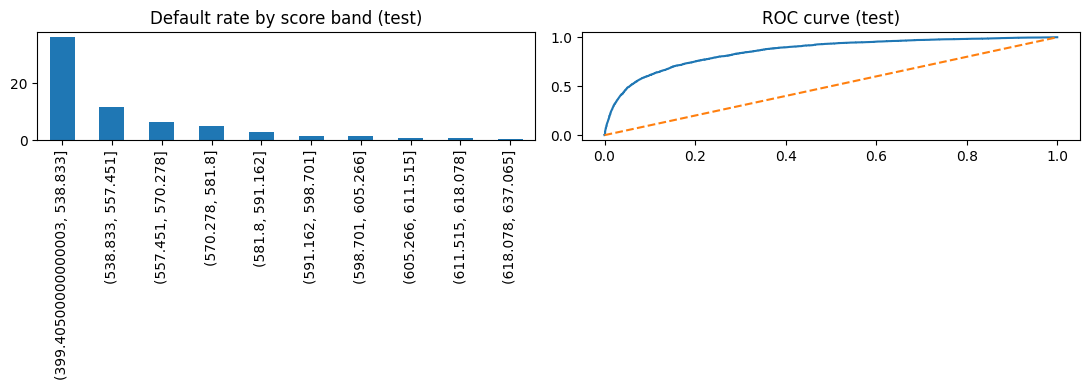

PSI: 0.0003


In [18]:
from sklearn.metrics import roc_auc_score, roc_curve
from scipy.stats import ks_2samp
import matplotlib.pyplot as plt

auc_train = roc_auc_score(y_train, -score_train)
auc_test = roc_auc_score(y_test, -score_test)
print("AUC train/test:", round(auc_train, 3), round(auc_test, 3))
print("Gini test:", round(2 * auc_test - 1, 3))
print("KS test:", round(ks_2samp(score_test[y_test == 1], score_test[y_test == 0]).statistic, 3))

bands = pd.qcut(score_test, 10)
band_table = y_test.groupby(bands, observed=True).agg(["count", "mean"])
print(band_table)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
band_table["mean"].mul(100).plot(kind="bar", ax=ax[0], title="Default rate by score band (test)")
fpr, tpr, _ = roc_curve(y_test, -score_test)
ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], "--"); ax[1].set_title("ROC curve (test)")
plt.tight_layout(); plt.show()

# PSI: is the test score distribution the same as the train one?
cuts = np.quantile(score_train, np.linspace(0, 1, 11)); cuts[0], cuts[-1] = -np.inf, np.inf
e = pd.Series(pd.cut(score_train, cuts)).value_counts(normalize=True).sort_index()
a = pd.Series(pd.cut(score_test, cuts)).value_counts(normalize=True).sort_index()
print("PSI:", round(((a - e) * np.log(a / e)).sum(), 4))

## Results
| Metric | Value |
|---|---|
| AUC (train / test) | 0.856 / 0.858 |
| Gini (test) | 0.716 |
| KS (test) | 0.554 |
| PSI (train vs test) | 0.0003 |

- Train and test AUC are almost identical, so there is no sign of overfitting.
- The default rate falls at every step from 36.2% in the lowest-scoring band to 0.5% in the highest, a 70-fold spread. The lowest 10% of scores contain about 54% of all defaulters and the lowest 20% about 71%.
- The ROC curve sits well above the diagonal: about 75% of defaulters are caught while flagging 20% of safe borrowers.
- PSI is near zero because the test set is a random slice of the same data. It demonstrates the method, and becomes meaningful when run on new borrowers months later.

## 7. Limitations and next steps
**Limitations**
- The split is random, not over time, so real-world performance would likely be lower than shown.
- The meaning of codes 96 and 98 is undocumented. If they are assigned after a borrower falls into arrears, the "Missing" bins could leak the outcome. In practice this should be confirmed with the data owner.
- The three past due variables overlap strongly, so their individual coefficients should not be over-interpreted.
- Utilisation values above 10 (241 rows) look like errors but were left in, which slightly dilutes the top risk bin.
- The debt ratio cutoff of 100 is a judgement of plausibility, not something the data proved.
- Several variables are weak (IV below 0.1). They were kept for the first model and could be tested for removal.

**Next steps**
- Validate out of time if dates were available.
- Merge adjacent bins that have similar WoE, for a simpler scorecard.
- Test whether the weakest variables can be removed without losing performance.
- Refit without the placeholder borrowers to see how much performance depends on them.
- Compare against a gradient boosting benchmark.
- Monitor PSI on incoming borrowers once the scorecard is in use.